(digits_feed_forward)=
# Feed-forward classifier on handwritten digits

This example walks through the pytensor-ml workflow on a small classification problem: build a network
as a symbolic graph, wrap it in a {class}`~pytensor_ml.model.Model`, compile a training step, and
compile a separate inference function to score held-out data. The network is a fully-connected
classifier with batch normalization {cite:p}`ioffe2015batchnorm` and dropout
{cite:p}`srivastava2014dropout`, trained on scikit-learn's 8x8 handwritten digits and evaluated with a
confusion matrix.

In [1]:
import pytensor

floatX = "float32"
pytensor.config.floatX = floatX

In [2]:
import matplotlib.pyplot as plt
import numpy as np

from scipy.special import softmax
from sklearn.datasets import load_digits
from sklearn.metrics import ConfusionMatrixDisplay, log_loss
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from tqdm.auto import tqdm

from pytensor_ml.activations import LeakyReLU
from pytensor_ml.layers import BatchNorm, Dropout, Input, Linear, Sequential
from pytensor_ml.loss import CrossEntropy
from pytensor_ml.model import Model
from pytensor_ml.optim import adagrad
from pytensor_ml.util import DataLoader

## Data

The digits are the test portion of the UCI optical recognition of handwritten digits dataset
{cite:p}`alpaydin1998digits`: 1,797 images of the digits 0 to 9. Each image is an 8x8 grid of integers
from 0 to 16, and each integer counts the inked pixels in one 4x4 block of the original 32x32 bitmap.
The network reads each image as a flat vector of 64 features.

The test set is a stratified fifth of the digits, with every class in the same proportion as in the
full data. The pixel scaler is fit on the training digits alone, so no test-set statistic reaches
training. The training labels are one-hot encoded for the cross-entropy loss below.

In [3]:
X, y = load_digits(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)

scaler = MinMaxScaler().fit(X_train)
X_train_normed = scaler.transform(X_train).astype(floatX)
X_test_normed = scaler.transform(X_test).astype(floatX)

y_train_onehot = OneHotEncoder().fit_transform(y_train[:, None]).toarray().astype(floatX)

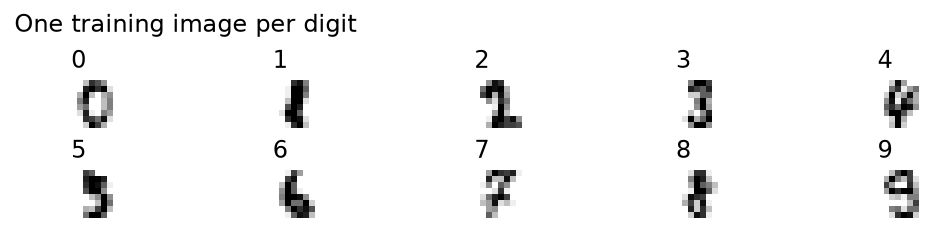

In [4]:
fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(7, 1.5), dpi=144, layout="constrained")

for digit, ax in enumerate(axes.flat):
    first_example = np.flatnonzero(y_train == digit)[0]
    ax.imshow(X_train[first_example].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"{digit}", loc="left")
    ax.set_axis_off()

fig.suptitle("One training image per digit", x=0.02, ha="left")
plt.show()

## Model

{class}`~pytensor_ml.layers.Input` declares a symbolic batch of 64-feature rows whose batch size is
left open. A {class}`~pytensor_ml.layers.Sequential` stack of two hidden blocks maps it to ten logits,
one per digit. Each block is a {class}`~pytensor_ml.layers.Linear` map,
{class}`~pytensor_ml.layers.BatchNorm`, {class}`~pytensor_ml.layers.Dropout`, and a
{class}`~pytensor_ml.activations.LeakyReLU` {cite:p}`maas2013rectifier`.

Batch normalization standardizes each unit over the mini-batch during training and keeps running
estimates of its mean and variance for inference. Dropout zeroes each unit with probability 0.5 during
training and rescales the survivors, which regularizes a network with 51,594 trainable weights fit to
1,437 training images.

Calling the network on the input builds the output graph without computing anything.
{class}`~pytensor_ml.model.Model` wraps that graph, and {meth}`~pytensor_ml.model.Model.initialize`
redraws every weight from its layer's initializer. Passing a seed makes the run reproducible.

In [5]:
X_in = Input("X_in", shape=(None, 64))

In [6]:
prediction_network = Sequential(
    Linear("Linear_1", n_in=64, n_out=256),
    BatchNorm("BatchNorm_1"),
    Dropout("Dropout_1", p=0.5, random_state=1),
    LeakyReLU(),
    Linear("Linear_2", n_in=256, n_out=128),
    BatchNorm("BatchNorm_2"),
    Dropout("Dropout_2", p=0.5, random_state=2),
    LeakyReLU(),
    Linear("Logits", n_in=128, n_out=10),
)

y_hat = prediction_network(X_in)
model = Model(y_hat, compile_kwargs={"mode": "NUMBA"}).initialize(seed=0)

## Training

{meth}`~pytensor_ml.model.Model.compile_train` builds the {class}`~pytensor_ml.loss.CrossEntropy` loss
against a target, differentiates it, folds in the batch norm running-statistic updates, and compiles a
one-step training function with the model's compile settings. The loss reads raw logits and one-hot
labels and averages over the batch. {func}`~pytensor_ml.optim.adagrad` {cite:p}`duchi2011adagrad`
supplies the update rule, which divides each weight's step by the square root of its accumulated
squared gradients.

Each call to `step` takes one 64-image mini-batch from a {class}`~pytensor_ml.util.DataLoader` and
applies one update. The loader reshuffles the training set each time it runs off the end, so 10,000
steps make about 445 passes over the data.

Every 100 steps the loop also scores the full training and test sets with the inference function. Both
curves below are computed with dropout off and batch norm reading its running statistics, which makes
them directly comparable. The distance between them is the generalization gap.

In [7]:
loss_fn = CrossEntropy(expect_onehot_labels=True, expect_logits=True, reduction="mean")

In [8]:
step = model.compile_train(adagrad(learning_rate=1e-3), loss_fn)

In [9]:
def inference_loss(model, X, digits):
    probabilities = softmax(model.predict(X), axis=-1)
    return log_loss(digits, probabilities, labels=np.arange(10))

In [10]:
loader = DataLoader(X_train_normed, y_train_onehot, random_state=0)
n_steps = 10_000
eval_every = 100

eval_steps = [0]
train_loss = [inference_loss(model=model, X=X_train_normed, digits=y_train)]
test_loss = [inference_loss(model=model, X=X_test_normed, digits=y_test)]

for step_number in tqdm(range(1, n_steps + 1)):
    X_batch, y_batch = loader()
    step(X_batch, y_batch)

    if step_number % eval_every == 0:
        eval_steps.append(step_number)
        train_loss.append(inference_loss(model=model, X=X_train_normed, digits=y_train))
        test_loss.append(inference_loss(model=model, X=X_test_normed, digits=y_test))

  0%|          | 0/10000 [00:00<?, ?it/s]

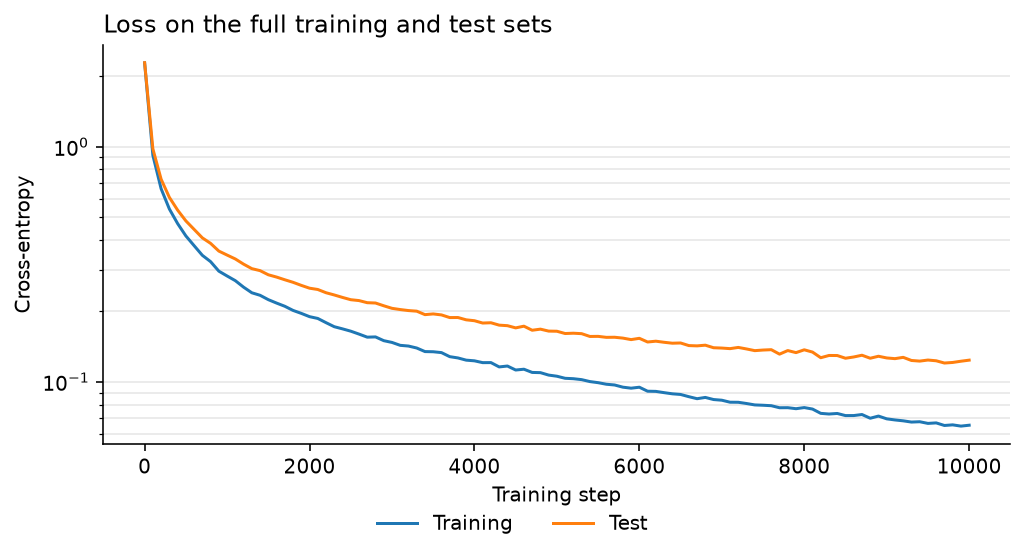

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.5), dpi=144, constrained_layout=True)
ax.plot(eval_steps, train_loss, label="Training")
ax.plot(eval_steps, test_loss, label="Test")
ax.set(xlabel="Training step", ylabel="Cross-entropy", yscale="log")
ax.set_title("Loss on the full training and test sets", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", which="both", alpha=0.3)

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles=handles,
    labels=labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.08),
    ncol=len(labels),
    frameon=False,
)
plt.show()

## Evaluation

{meth}`~pytensor_ml.model.Model.predict` compiles a separate inference function from the same graph. It
skips dropout and normalizes with the batch norm running statistics, so each prediction depends only on
its own input. The predicted digit is the one with the largest logit.

The confusion matrices count digits by true and predicted class, for the training set and for the
held-out test set. Correct predictions fall on the diagonal, and each off-diagonal cell counts one kind
of mistake.

In [12]:
y_train_pred = np.argmax(model.predict(X_train_normed), axis=-1)
y_test_pred = np.argmax(model.predict(X_test_normed), axis=-1)

train_accuracy = np.mean(y_train_pred == y_train)
test_accuracy = np.mean(y_test_pred == y_test)

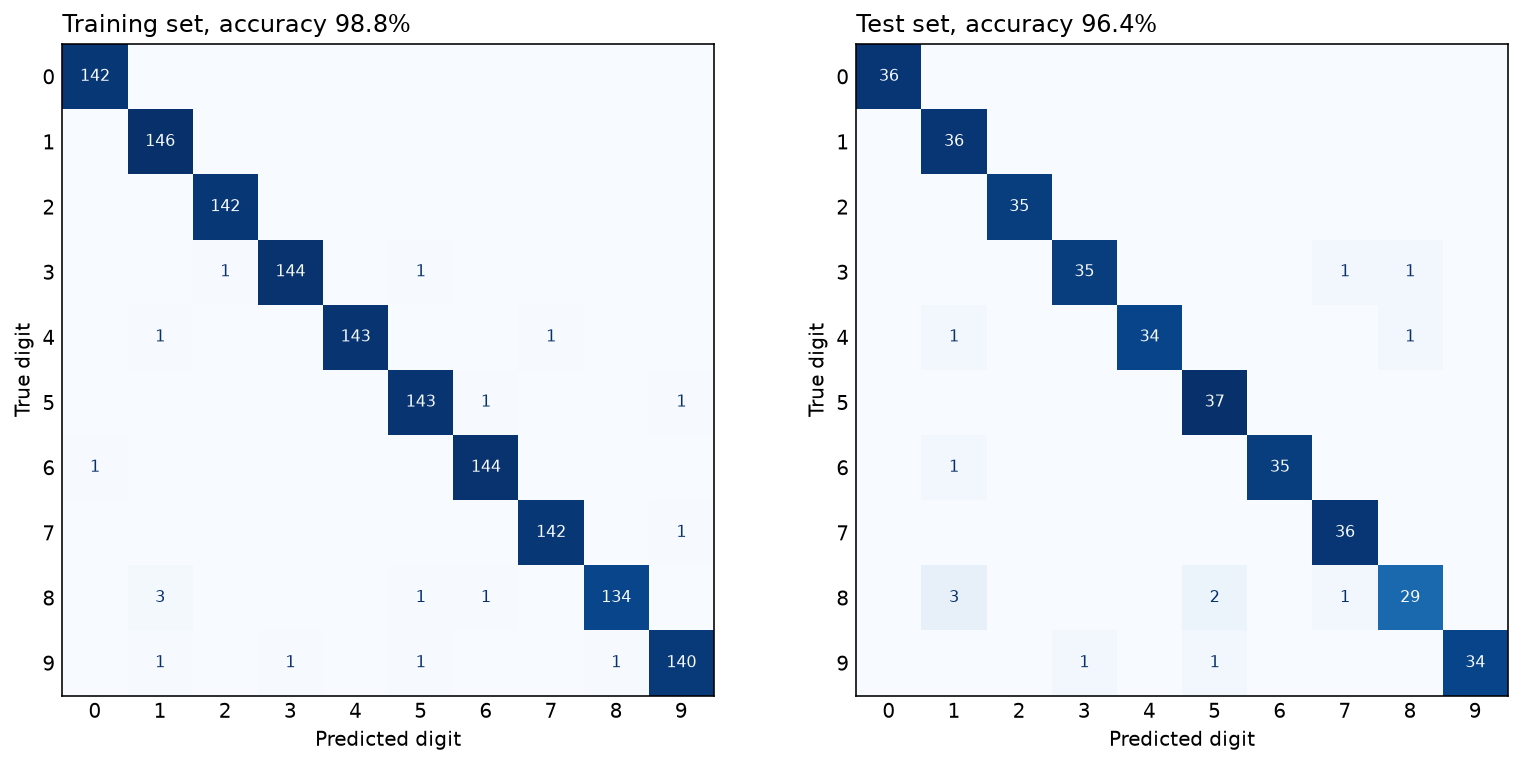

In [13]:
fig, axes = plt.subplots(ncols=2, figsize=(11, 5.2), dpi=144, constrained_layout=True)
panels = [
    ("Training", y_train, y_train_pred, train_accuracy),
    ("Test", y_test, y_test_pred, test_accuracy),
]

for ax, (split_name, y_true, y_predicted, accuracy) in zip(axes, panels, strict=True):
    confusion_display = ConfusionMatrixDisplay.from_predictions(
        y_true, y_predicted, cmap="Blues", ax=ax, colorbar=False, text_kw={"fontsize": 8}
    )
    for text in confusion_display.text_.ravel():
        text.set_visible(text.get_text() != "0")

    ax.set(xlabel="Predicted digit", ylabel="True digit")
    ax.set_title(f"{split_name} set, accuracy {accuracy:.1%}", loc="left")
    ax.tick_params(length=0)

plt.show()

## Next steps

- The {doc}`quick example </index>` trains a smaller network with Adam {cite:p}`kingma2015adam` under
  a cosine learning-rate schedule, composed with gradient clipping by {func}`~pytensor_ml.optim.chain`.
- {doc}`/sharp_edges` covers where pytensor-ml behaves differently from PyTorch, Keras, and the JAX
  libraries.
- The {doc}`API reference </api>` documents each layer, loss, and optimizer used here, alongside the
  others the library provides.

## References

```{bibliography}
```

## Authors

- Created by Jesse Grabowski, April 20, 2024
- Updated by Pham Nguyen Hung, January 26, 2025
- Updated by Jesse Grabowski, August 26, 2026
- Updated by Jesse Grabowski, November 7, 2026

## Watermark

In [14]:
%load_ext watermark
%watermark -n -u -v -iv -m -w

Last updated: Sat, 07 Nov 2026

Python implementation: CPython
Python version       : 3.14.10
IPython version      : 9.16.1

Compiler    : Clang 20.1.8 
OS          : Darwin
Release     : 25.6.0
Machine     : arm64
Processor   : arm
CPU cores   : 14
Architecture: 64bit

matplotlib : 3.11.2
numpy      : 2.5.4
pytensor   : 3.3.8
pytensor_ml: 0.4.0
scipy      : 1.18.1
sklearn    : 1.9.1
tqdm       : 4.70.1

Watermark: 2.6.0

